# Dynamic Thermal Modelling and Energy-Efficient Cooling of an AI Data Hall

**Main notebook** — Mathematical Modelling (MAC F314), BITS Pilani K K Birla Goa Campus.

**Flow:** problem and assumptions → thermal equations → fixed-setpoint PI (B1) → load-adaptive PI (B2) → energy/safety comparison → compact optimal-control (OC) benchmark → sensitivity → conclusions.

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What this notebook claims, and what it does not</b><br>
<ul><li><b>All parameters are illustrative [ILL]</b> (plausible orders of magnitude, not measured). Only <b>two synthetic step scenarios</b> are tested, with no real workload or weather data, and there is <b>no real-facility validation</b>. Every number is a model result.</li><li>The checks below show that the code solves <i>our</i> equations correctly. That is numerical <b>verification</b>, not real-world validation.</li><li><b>A saving is claimed only when both compared runs</b> are complete, stay within limits on <b>both the 5 s and the 1 s</b> replay grids, settle (PI), and return to their own start state (terminal checks). Otherwise the result is shown without a savings claim.</li><li>The OC benchmark is <b>offline, perfect-foresight and best-found</b>: not deployable and not globally optimal.</li></ul>
</div>

<div style="background:#fdecef;border-left:6px solid #c0392b;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Loaded versus recomputed</b><br>
<ul><li><b>Recomputed here:</b> model checks, PI gain design, all PI runs (the B1/B2 comparison and the sensitivity sweep), the electricity accounting, every replay of the OC commands, the OC constraint and objective checks, and the LP lower bounds.</li><li><b>Loaded</b> (only the expensive IPOPT optimisation): the best-found OC command and state arrays from <code>artifacts/oc_best_found.npz</code>. They were exported by <code>scripts/export_oc_artifacts.py</code>, which re-ran notebook 04's own code unchanged and confirmed every exported value against notebook 04's printed results. Set <code>RUN_FULL_OC = True</code> to re-optimise instead (about 15–20 min).</li><li>The full verification suites remain in the supporting notebooks 01–05 (50 + 36 + 52 + 197 + 152 checks).</li></ul>
</div>

In [1]:
import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path("..").resolve()                     # project root; this notebook lives in notebook/
sys.path.insert(0, str(ROOT / "src"))
import thermal_model as tm
import controllers as ct
import optimal_control as oc

FIG = ROOT / "figures" / "main"
FIG.mkdir(parents=True, exist_ok=True)
ART = ROOT / "artifacts"
T_START = time.perf_counter()
p = tm.Params()
H = 3600.0

# ---- tolerances and settings: identical to notebooks 03-05 (declared before any run) ----
HORIZON = 17 * H              # common closed-cycle horizon, s
FINE_DT, FINE_DT_CHECK = 5.0, 1.0   # replay grids: 5 s (energy, settling) and 1 s (safety, refinement)
TOL_SETTLE = 0.1              # K
TOL_SAFETY = 1e-6             # K, on BOTH grids
TOL_TERMINAL = 1e-3           # K
TOL_DU = 1e-4                 # |dU| max g <= TOL_DU E_cool
TOL_FEAS_K, TOL_FEAS_W = 1e-6, 1e-3   # feasibility for the discrete OC problem
TOL_REPLAY = 1e-6             # K, replay vs optimiser states
TOL_LP = 1e-7                 # relative, recomputed vs stored LP bound
T_A_BAND, T_S_MAX = (18.0, 27.0), 40.0   # illustrative limits
DTS = (60, 300)
RUN_FULL_OC = False           # True: re-run the IPOPT optimisation instead of loading artifacts (slow)

results = []


def record(cid, desc, value, criterion, passed):
    results.append((cid, desc, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {cid}: {desc}\n        measured: {value}   criterion: {criterion}")


def save_fig(fig, name):
    for ext in ("png", "eps", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200 if ext == "png" else None, bbox_inches="tight")


BLUE, ORANGE, GREEN, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#1f1f1d", "#6b6b66", "#e4e4e0"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})
import casadi
print(f"python {sys.version.split()[0]}, numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, "
      f"casadi {casadi.__version__}")
print(f"project root: {ROOT}")

python 3.14.7, numpy 2.5.4, scipy 1.18.1, matplotlib 3.11.2, casadi 3.8.2
project root: /tmp/claude-1000/-home-melenin-Projects-MM-proj/adc9f93e-af89-4392-b565-ebaa13200818/scratchpad/clean/MM_project


## 1. Problem and assumptions

**The question.** An AI data hall turns almost all of its electrical power into heat, and the cooling plant must remove that heat. Removing heat costs electricity, and *how much* depends on the chiller's efficiency, its coefficient of performance (COP), which improves when the room air is warmer. The question is therefore:

> How much cooling electricity can a controller save by keeping the air warmer, and what safety margin does that cost?

<div style="background:#f3eefb;border-left:6px solid #7b52c4;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Modelling assumptions</b><br>
<ol><li><b>Two lumped temperatures.</b> All IT equipment is one thermal mass at $T_s$; the room air is another at $T_a$. There are no hot spots, no CFD and no humidity.</li><li>All IT electrical power $P_{IT}$ becomes heat in the equipment. Server power does not depend on temperature ($\kappa=0$).</li><li>Heat flows are linear in temperature differences: $UA_s(T_s-T_a)$ from equipment to air, and $UA_e(T_{out}-T_a)$ through the envelope.</li><li>The cooling plant removes heat $Q_c\in[0,Q_{\max}]$ from the air. Its electricity is $Q_c/\mathrm{COP}$ with a Carnot-fraction COP (§2.3). There is no free cooling, no part-load curve and no fan power.</li><li>Commands are held constant between controller updates (zero-order hold), every $\Delta t=60$ s or $300$ s.</li><li>The limits are illustrative: air 18–27 °C, lumped equipment ≤ 40 °C. The 40 °C value is <b>not</b> a certified chip limit.</li></ol>
</div>

In [2]:
print("Parameters (SI) — [ILL] = illustrative:")
for name, val, unit, tag in (("rho", p.rho, "kg/m^3", "STD"), ("c_p", p.c_p, "J/(kg K)", "STD"), ("V", p.V, "m^3", "ILL"),
                             ("C_a = rho c_p V", p.C_a, "J/K", "ILL"), ("C_s", p.C_s, "J/K", "ILL"), ("UA_s", p.UA_s, "W/K", "ILL"),
                             ("UA_e", p.UA_e, "W/K", "ILL"), ("Q_max", p.Q_max, "W_th", "ILL"), ("eta_II", p.eta_II, "-", "ILL"),
                             ("dT_ev", p.dT_ev, "K", "ILL"), ("dT_cd", p.dT_cd, "K", "ILL"), ("COP_cap", p.COP_cap, "-", "ILL")):
    print(f"  {name:16s} = {val:12.6g} {unit:9s} [{tag}]")

Parameters (SI) — [ILL] = illustrative:
  rho              =          1.2 kg/m^3    [STD]
  c_p              =         1005 J/(kg K)  [STD]
  V                =         3000 m^3       [ILL]
  C_a = rho c_p V  =    3.618e+06 J/K       [ILL]
  C_s              =      2.5e+07 J/K       [ILL]
  UA_s             =      66666.7 W/K       [ILL]
  UA_e             =         2000 W/K       [ILL]
  Q_max            =      1.5e+06 W_th      [ILL]
  eta_II           =         0.45 -         [ILL]
  dT_ev            =           12 K         [ILL]
  dT_cd            =            8 K         [ILL]
  COP_cap          =           10 -         [ILL]


## 2. Thermal equations

### 2.1 Heat balance (first law for each lumped mass)

Rate of change of stored heat = heat in − heat out:

$$C_s\,\dot T_s = P_{IT} - UA_s\,(T_s-T_a), \qquad
C_a\,\dot T_a = UA_s\,(T_s-T_a) + UA_e\,(T_{out}-T_a) - Q_c .$$

In matrix form $\dot x = A x + B u + E d$, with $x=[T_s,T_a]^\top$, $u=Q_c$ and $d=[P_{IT},T_{out}]^\top$:

$$A=\begin{bmatrix}-UA_s/C_s & UA_s/C_s\\ UA_s/C_a & -(UA_s+UA_e)/C_a\end{bmatrix},\quad
B=\begin{bmatrix}0\\-1/C_a\end{bmatrix},\quad
E=\begin{bmatrix}1/C_s&0\\0&UA_e/C_a\end{bmatrix}.$$

**Stored energy.** $U=C_sT_s+C_aT_a$ satisfies $\dot U = P_{IT} + UA_e(T_{out}-T_a) - Q_c$. Integrated over a run,

$$E_Q = E_{IT} + E_{env} - \Delta U .$$

So over a closed cycle ($\Delta U=0$), the heat removed equals the heat released plus the heat that leaked in.

**Equilibrium.** Setting $\dot x=0$ gives $T_a^\ast = T_{out}+(P_{IT}-Q_c)/UA_e$ and $T_s^\ast=T_a^\ast+P_{IT}/UA_s$.
- The cooling that holds a chosen air temperature is $Q_c = P_{IT}+UA_e(T_{out}-T_a)$.
- The equipment always runs $P_{IT}/UA_s$ kelvin above the air: **15 K at 1 MW**. That number drives everything below.

### 2.2 Exact zero-order-hold (ZOH) discretisation
<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Algorithm: augmented matrix exponential (Van Loan, 1978)</b><br>
With the input $w=[Q_c,P_{IT},T_{out}]$ constant on $[t,t+h)$, the exact solution is $x(t+h)=\Phi x(t)+\Gamma w$ with $\Phi=e^{Fh}$ and $\Gamma=\int_0^h e^{Fs}\,ds\,H$. Both come from <b>one</b> matrix exponential, $\exp\!\Big(\begin{bmatrix}F&H\\0&0\end{bmatrix}h\Big)=\begin{bmatrix}\Phi&\Gamma\\0&I\end{bmatrix}$. We augment the state with the running integrals $E_Q,E_{IT},E_{env}$, so the energy totals are propagated <i>exactly</i> together with the temperatures. There is no time-step error. The reference check is SciPy's stiff Radau solver, restarted at every input change.
</div>

### 2.3 Cooling electricity and the COP

The chiller moves heat from the evaporator ($T_{ev}=T_a-12$ K) to the condenser ($T_{cd}=T_{out}+8$ K). We take a fixed fraction $\eta_{II}=0.45$ of the Carnot COP (temperatures in kelvin):

$$\mathrm{COP}=\eta_{II}\,\frac{T_{ev}}{T_{cd}-T_{ev}},\qquad P_{cool}=\frac{Q_c}{\mathrm{COP}},\qquad E_{cool}=\int_0^{t_f}\frac{Q_c}{\mathrm{COP}(T_a,T_{out})}\,dt .$$

- The model is used only inside its stated domain: positive lift and COP ≤ 10. Outside it the code stops instead of extrapolating.
- **Heat removed (kWh$_{th}$) and electricity used (kWh$_e$) are never mixed.**
- $E_{cool}$ is integrated with Simpson's rule on every 5 s segment, using exactly propagated midpoints, and checked against an independent 0.5 s trapezoid sum.

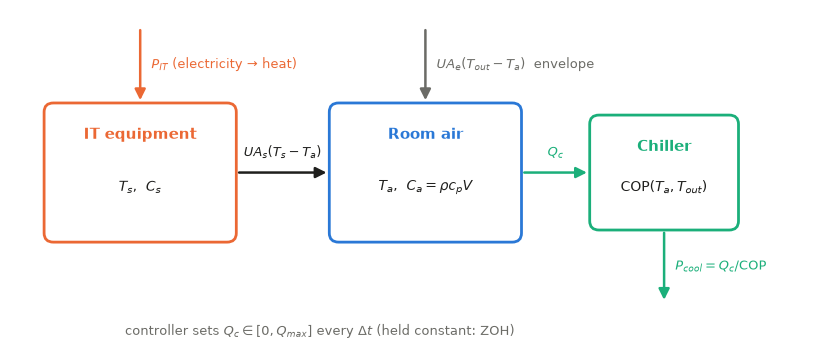

In [3]:
# Model diagram (source code for the schematic used in the report; drawn with matplotlib, no external images)
fig, ax = plt.subplots(figsize=(10.4, 4.4))
ax.set_xlim(0, 13); ax.set_ylim(-0.4, 5.2); ax.axis("off")


def node(x, y, w, h, title, body, col):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15", fc="white", ec=col, lw=2))
    ax.text(x + w / 2, y + h - 0.35, title, ha="center", va="top", fontsize=11, color=col, weight="bold")
    ax.text(x + w / 2, y + h / 2 - 0.25, body, ha="center", va="center", fontsize=10, color=INK)


def arrow(x0, y0, x1, y1, label, col):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=16, lw=1.8, color=col))
    if x0 == x1:   # vertical arrow: label beside the shaft
        ax.text(x0 + 0.18, (y0 + y1) / 2, label, ha="left", va="center", fontsize=9.5, color=col)
    else:          # horizontal arrow: label above the shaft
        ax.text((x0 + x1) / 2, y0 + 0.22, label, ha="center", va="bottom", fontsize=9.5, color=col)


node(0.6, 1.4, 3.0, 2.2, "IT equipment", "$T_s$,  $C_s$", ORANGE)
node(5.2, 1.4, 3.0, 2.2, "Room air", "$T_a$,  $C_a=\\rho c_p V$", BLUE)
node(9.4, 1.6, 2.3, 1.8, "Chiller", "COP$(T_a,T_{out})$", GREEN)
arrow(2.1, 4.9, 2.1, 3.65, "$P_{IT}$ (electricity → heat)", ORANGE)
arrow(3.65, 2.5, 5.15, 2.5, "$UA_s(T_s-T_a)$", INK)
arrow(6.7, 4.9, 6.7, 3.65, "$UA_e(T_{out}-T_a)$  envelope", MUTED)
arrow(8.25, 2.5, 9.35, 2.5, "$Q_c$", GREEN)
arrow(10.55, 1.55, 10.55, 0.35, "$P_{cool}=Q_c/\\mathrm{COP}$", GREEN)
ax.text(5.0, -0.2, "controller sets $Q_c\\in[0,Q_{max}]$ every $\\Delta t$ (held constant: ZOH)", ha="center", fontsize=9.5, color=MUTED)
save_fig(fig, "fig1_model_diagram"); plt.show()

In [4]:
# Worked numbers and fast model checks
A, B, E, G = tm.system_matrices(p)
lam = tm.eigenvalues(p)
tr, det = np.trace(A), np.linalg.det(A)
lam_formula = np.sort((tr + np.array([-1, 1]) * np.sqrt(tr**2 - 4 * det)) / 2)
tau_f, tau_s = tm.time_constants(p)
record("M1", "eigenvalues of A: symmetric-form solver vs trace/determinant formula; both negative (stable)",
       f"lambda = {lam[0]:.6e}, {lam[1]:.6e} 1/s; tau_fast = {tau_f:.2f} s, tau_slow = {tau_s/H:.3f} h",
       "rel diff < 1e-10, both < 0", np.allclose(lam, lam_formula, rtol=1e-10) and np.all(lam < 0))

Q0 = tm.holding_cooling(p, 24.0, 0.6e6, 30.0)
x_eq = tm.equilibrium(p, Q0, 0.6e6, 30.0)
res_eq = np.max(np.abs(A @ x_eq + G @ np.array([Q0, 0.6e6, 30.0])))
print(f"Worked equilibrium (P_IT = 0.6 MW, T_out = 30 C, hold T_a = 24 C): Q_c = 0.6 MW + 2000 W/K x 6 K = {Q0/1e3:.0f} kW_th; "
      f"T_s = 24 + 0.6e6/(1e6/15) = {x_eq[0]:.1f} C")
record("M2", "worked equilibrium satisfies A x + G w = 0", f"residual {res_eq:.1e} K/s", "< 1e-15 K/s", res_eq < 1e-15)

rng = np.random.default_rng(0)
t_grid = np.concatenate([[0.0], np.cumsum(rng.uniform(30, 900, 40))])
W = np.column_stack([rng.uniform(0, 1.5e6, 40), rng.uniform(0.3e6, 1.2e6, 40), rng.uniform(25, 38, 40)])
X_zoh = tm.simulate_zoh(p, [33.0, 24.0], t_grid, W)
X_ivp = tm.simulate_ivp(p, [33.0, 24.0], t_grid, W)
d_zoh = np.max(np.abs(X_zoh[:, :2] - X_ivp[:, :2]))
record("M3", "exact ZOH vs independent Radau (rtol 1e-10, restarted at input changes), 40 random intervals",
       f"max |dT| = {d_zoh:.1e} K", "< 1e-6 K", d_zoh < 1e-6)
rel_bal = abs(tm.energy_balance_residual(p, X_zoh)) / X_zoh[-1, 3]
record("M4", "energy balance E_Q = E_IT + E_env - dU with exactly propagated integrals", f"relative residual {rel_bal:.1e}", "< 1e-9", rel_bal < 1e-9)
for Ta, To in ((24.0, 30.0), (26.0, 30.0), (27.0, 30.0)):
    T_ev, T_cd = Ta - p.dT_ev + 273.15, To + p.dT_cd + 273.15
    print(f"COP(T_a = {Ta:.0f} C, T_out = {To:.0f} C) = 0.45 x {T_ev:.2f} / ({T_cd:.2f} - {T_ev:.2f}) = {tm.cop(p, Ta, To):.3f}")

[PASS] M1: eigenvalues of A: symmetric-form solver vs trace/determinant formula; both negative (stable)
        measured: lambda = -2.157753e-02, -6.831695e-05 1/s; tau_fast = 46.34 s, tau_slow = 4.066 h   criterion: rel diff < 1e-10, both < 0
Worked equilibrium (P_IT = 0.6 MW, T_out = 30 C, hold T_a = 24 C): Q_c = 0.6 MW + 2000 W/K x 6 K = 612 kW_th; T_s = 24 + 0.6e6/(1e6/15) = 33.0 C
[PASS] M2: worked equilibrium satisfies A x + G w = 0
        measured: residual 5.6e-17 K/s   criterion: < 1e-15 K/s


[PASS] M3: exact ZOH vs independent Radau (rtol 1e-10, restarted at input changes), 40 random intervals
        measured: max |dT| = 7.5e-11 K   criterion: < 1e-6 K
[PASS] M4: energy balance E_Q = E_IT + E_env - dU with exactly propagated integrals
        measured: relative residual 3.4e-15   criterion: < 1e-9
COP(T_a = 24 C, T_out = 30 C) = 0.45 x 285.15 / (311.15 - 285.15) = 4.935
COP(T_a = 26 C, T_out = 30 C) = 0.45 x 287.15 / (311.15 - 287.15) = 5.384
COP(T_a = 27 C, T_out = 30 C) = 0.45 x 288.15 / (311.15 - 288.15) = 5.638


## 3. Fixed-setpoint PI controller (B1)

The PI law runs every $\Delta t$ seconds with error $e_k=T_{a,k}-T_{set}$; a positive error means the air is too warm, so cooling increases:

$$Q_{c,k}=\mathrm{sat}_{[0,\,Q_{\max}]}\big(K_p e_k + I_k\big),\qquad I_k=I_{k-1}+K_i\,\Delta t\,e_k .$$

The command is held constant until the next update (ZOH).

<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Anti-windup by conditional integration</b><br>
If an update would push the command further past a limit, the integrator is advanced only up to that limit: $I_k=\max(I_{k-1},\,Q_{\max}-K_pe_k)$ at the top, and $I_k=\min(I_{k-1},\,-K_pe_k)$ at the bottom. This stops the integrator winding up while the actuator is saturated (see Åström & Murray, 2021). Updates that move back into range are always accepted.
</div>

<div style="background:#e8f1fc;border-left:6px solid #2a78d6;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Gain design: tuned for stability, not for energy</b><br>
Without saturation, the loop state $z_k=[T_s,T_a,I_{k-1}]$ evolves as $z_{k+1}=Mz_k$, with $M=\begin{bmatrix}\Phi+(K_p+K_i\Delta t)\Gamma_u c & \Gamma_u\\ K_i\Delta t\, c & 1\end{bmatrix}$ and $c=[0,1]$. The loop is stable if and only if the spectral radius $\rho(M)<1$. On a grid of $(K_p,K_i)$ we pick the pair with the smallest $\rho(M)$ that also stays stable at <b>twice</b> the gains (a robustness margin). The gains are designed once per update interval and <b>never retuned for energy</b>.
</div>

**Setpoint.** $T_{set}=\min(27,\ 40-P_{IT,\max}/UA_s)-m = \min(27, 40-15)-1 = 24$ °C. This is safe at the 1 MW peak load with a provisional margin $m=1$ K.

In [5]:
for dt, g in ct.STAGE2_GAINS.items():
    g_re, info = ct.design_gains(p, float(dt), ct.STAGE2_KP_GRID, ct.STAGE2_KI_GRID, gain_margin=2.0)
    rho = ct.spectral_radius(p, g)
    record(f"P1-{dt}", f"dt = {dt} s: gain-design rule reproduces the stored gains exactly; loop stable",
           f"Kp = {g.Kp:.1f} W/K, Ki = {g.Ki:.2f} W/(K s); rho(M) = {rho:.4f}; rho at 2x gains = {info['rho_margin']:.4f}",
           "bit-identical, rho < 1", g_re == g and rho < 1)
print("Note: the 60 s gains are unstable at 300 s, so each interval has its own gains (notebook 02).")

[PASS] P1-60: dt = 60 s: gain-design rule reproduces the stored gains exactly; loop stable
        measured: Kp = 8096.1 W/K, Ki = 630.96 W/(K s); rho(M) = 0.6862; rho at 2x gains = 0.8277   criterion: bit-identical, rho < 1


[PASS] P1-300: dt = 300 s: gain-design rule reproduces the stored gains exactly; loop stable
        measured: Kp = 0.0 W/K, Ki = 199.53 W/(K s); rho(M) = 0.5649; rho at 2x gains = 0.9181   criterion: bit-identical, rho < 1
Note: the 60 s gains are unstable at 300 s, so each interval has its own gains (notebook 02).


## 4. Load-adaptive PI controller (B2)

Same PI law, gains, limits and anti-windup. **Only the setpoint changes**: at every update it is recomputed from the measured load,

$$T_{set}=\mathrm{clip}\Big(\min\big(27,\ 40-P_{IT}/UA_s\big)-m,\ 18,\ 27\Big).$$

At steady state the equipment sits $P_{IT}/UA_s$ above the air, so this is the warmest air temperature that keeps the equipment at or below 40 °C, minus a margin $m$ (default 1 K, provisional).

**Worked values ($m=1$):**
- at 1.0 MW: $\min(27, 40-15)-1=24$ °C (the same as B1);
- at 0.6 MW: $\min(27, 40-9)-1=26$ °C;
- at 0.8 MW: $\min(27, 40-12)-1=26$ °C.

**Why warmer can save energy (quasi-steady prediction).** At $T_{out}=30$ °C, COP(26 °C) = 5.384 versus COP(24 °C) = 4.935, so each joule removed costs 8.3 % less electricity. A warmer room also gains a little less heat through the envelope. The prediction below is made **before** any simulation.

In [6]:
PD = ct.PiecewiseDisturbance
SCEN = {   # synthetic closed-cycle step traces (defined here in code; no external data)
    "S1":  dict(dist=PD([0, 1*H, 9*H], [0.6e6, 1.0e6, 0.6e6], [30.0, 30.0, 30.0]), events=[(1*H, 9*H), (9*H, HORIZON)],
                pieces=[(1.0, 0.6e6, 30.0), (8.0, 1.0e6, 30.0), (8.0, 0.6e6, 30.0)],
                title="S1: load 0.6 → 1.0 MW (1 h) → 0.6 MW (9 h), $T_{out}$ 30 °C"),
    "S2c": dict(dist=PD([0, 1*H, 9*H], [0.8e6, 0.8e6, 0.8e6], [30.0, 35.0, 30.0]), events=[(1*H, 9*H), (9*H, HORIZON)],
                pieces=[(1.0, 0.8e6, 30.0), (8.0, 0.8e6, 35.0), (8.0, 0.8e6, 30.0)],
                title="S2c: 0.8 MW, $T_{out}$ 30 → 35 °C (1 h) → 30 °C (9 h)"),
}
PRED = {}
for sid, s in SCEN.items():
    e = {}
    for lab, rule in (("B1", lambda P: 24.0), ("B2", lambda P: ct.adaptive_setpoint(P, p.UA_s))):
        e[lab] = sum((P + p.UA_e * (To - rule(P))) / tm.cop(p, rule(P), To) * h for h, P, To in s["pieces"]) / 1e3
    PRED[sid] = (e["B1"] - e["B2"]) / e["B1"]
    print(f"PREDICTION {sid}: B1 {e['B1']:.1f} kWh_e, B2 {e['B2']:.1f} kWh_e  ->  predicted saving {100*PRED[sid]:+.2f} %")

PREDICTION S1: B1 2756.5 kWh_e, B2 2656.8 kWh_e  ->  predicted saving +3.62 %
PREDICTION S2c: B1 3069.4 kWh_e, B2 2819.3 kWh_e  ->  predicted saving +8.15 %


## 5. Energy and safety comparison (B1 vs B2), plus the sensitivity runs

### Protocol

- **Same horizon and traces.** Every run uses the same 17 h closed-cycle trace: disturbances change at 1 h and 9 h and return to their starting values. This leaves 8 h of recovery after the last change.
- **Own-equilibrium start.** Each controller starts at **its own** equilibrium (its setpoint at the starting load) and must return to that same state at the end. The initial states therefore differ, and each one is printed.
- **Two replay grids.** Every run is replayed on a 5 s grid (energy, settling) and a 1 s grid (safety, refinement).
- **Strict eligibility.** A run is eligible only if it is complete, within limits on both grids, settled within ±0.1 K of its setpoint before each change and at the end, and returns to its start state ($|\Delta T|\le10^{-3}$ K, $\Delta U$ negligible).

The same function also runs the sensitivity sweep used in §7: B2 margin $m\in\{0.5,1,1.5,2\}$ K and B1 setpoint $\in\{23,24,25\}$ °C.

In [7]:
CTRLS = [("B1", 23.0), ("B1", 24.0), ("B1", 25.0), ("B2", 0.5), ("B2", 1.0), ("B2", 1.5), ("B2", 2.0)]


def name(kind, v):
    return f"B1 {v:.0f} C" if kind == "B1" else f"B2 m={v:g} K"


def make_ctrl(kind, v, dt, P0):
    g = ct.STAGE2_GAINS[dt]
    if kind == "B1":
        return ct.FixedSetpointPI(g, v, Q_min=0.0, Q_max=p.Q_max)
    return ct.LoadAdaptivePI(g, ct.adaptive_setpoint(P0, p.UA_s, margin=v), Q_min=0.0, Q_max=p.Q_max, UA_s=p.UA_s, margin=v)


def run_pi(kind, v, dt, dist, fine_dt):
    P0, To0 = dist.at(0.0)
    ctrl = make_ctrl(kind, v, dt, P0)
    Q0 = tm.holding_cooling(p, ctrl.T_set, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)            # own equilibrium
    ctrl.initialize(Q0)                            # bumpless start
    res = ct.simulate_closed_loop(p, ctrl, dist, x0, HORIZON, fine_dt=fine_dt)
    res.meta["x0"] = x0
    return res


def assess(r5, r1, events):
    e = ct.energy_summary(p, r5)
    v5 = ct.limit_violations(r5, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    v1 = ct.limit_violations(r1, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    on = r5.Q[:-1] > 0
    g_max = np.nanmax(r5.P_cool[:-1][on] / r5.Q[:-1][on]) if on.any() else 0.0
    term_ok = (abs(e["dT_s_end_K"]) <= TOL_TERMINAL and abs(e["dT_a_end_K"]) <= TOL_TERMINAL
               and abs(e["dU_J"]) * g_max <= TOL_DU * r5.E_cool[-1])
    settled = all(ct.event_metrics(r5, a, b, tol=TOL_SETTLE)["settling_time"] is not None for a, b in events) if events else True
    reasons = ([] if e["complete"] else ["stopped"]) + ([] if v5["within_limits"] else ["unsafe (5 s)"]) + \
              ([] if v1["within_limits"] or not v5["within_limits"] else ["unsafe (1 s only)"]) + \
              ([] if settled else ["not settled"]) + ([] if term_ok else ["terminal check failed"])
    mv = lambda v: max(v["max_T_a_over"], v["max_T_a_under"], v["max_T_s_over"])
    return {"e": e, "v5": v5, "v1": v1, "mv5": mv(v5), "mv1": mv(v1), "term_ok": term_ok, "settled": settled,
            "headroom": min(27 - v1["T_a_max"], v1["T_a_min"] - 18, 40 - v1["T_s_max"]), "eligible": not reasons, "reasons": reasons}


t0 = time.perf_counter()
R5, R1, AS = {}, {}, {}
for sid, s in SCEN.items():
    for dt in DTS:
        for kind, v in CTRLS:
            key = (sid, dt, kind, v)
            R5[key] = run_pi(kind, v, dt, s["dist"], FINE_DT)
            R1[key] = run_pi(kind, v, dt, s["dist"], FINE_DT_CHECK)
            AS[key] = assess(R5[key], R1[key], s["events"])
print(f"{len(R5)} PI runs x 2 grids simulated in {time.perf_counter() - t0:.0f} s")
for sid in SCEN:
    for kind, v in CTRLS:
        x0 = R5[(sid, 60, kind, v)].meta["x0"]
        print(f"  initial state {sid:3s} {name(kind, v):10s}: T_a = {x0[1]:.2f} C, T_s = {x0[0]:.2f} C")

28 PI runs x 2 grids simulated in 96 s
  initial state S1  B1 23 C   : T_a = 23.00 C, T_s = 32.00 C
  initial state S1  B1 24 C   : T_a = 24.00 C, T_s = 33.00 C
  initial state S1  B1 25 C   : T_a = 25.00 C, T_s = 34.00 C
  initial state S1  B2 m=0.5 K: T_a = 26.50 C, T_s = 35.50 C
  initial state S1  B2 m=1 K  : T_a = 26.00 C, T_s = 35.00 C
  initial state S1  B2 m=1.5 K: T_a = 25.50 C, T_s = 34.50 C
  initial state S1  B2 m=2 K  : T_a = 25.00 C, T_s = 34.00 C
  initial state S2c B1 23 C   : T_a = 23.00 C, T_s = 35.00 C
  initial state S2c B1 24 C   : T_a = 24.00 C, T_s = 36.00 C
  initial state S2c B1 25 C   : T_a = 25.00 C, T_s = 37.00 C
  initial state S2c B2 m=0.5 K: T_a = 26.50 C, T_s = 38.50 C
  initial state S2c B2 m=1 K  : T_a = 26.00 C, T_s = 38.00 C
  initial state S2c B2 m=1.5 K: T_a = 25.50 C, T_s = 37.50 C
  initial state S2c B2 m=2 K  : T_a = 25.00 C, T_s = 37.00 C


In [8]:
# fast checks on every PI run: energy balance, integration refinement, terminal closure; independent quadrature on B1-24/B2-1
def independent_E_cool(res, dist, x0, h=0.5):
    t_end = res.t[-1]
    grid = np.unique(np.concatenate([np.arange(0.0, t_end, h), res.log["t"], dist.times[dist.times < t_end], [t_end]]))
    k = np.searchsorted(res.log["t"], grid[:-1], side="right") - 1
    Q = res.log["u"][k]
    PT = np.array([dist.at(t) for t in grid[:-1]])
    X = tm.simulate_zoh(p, x0, grid, np.column_stack([Q, PT[:, 0], PT[:, 1]]))
    on = Q > 0
    gl = np.zeros_like(Q); gr = np.zeros_like(Q)
    gl[on] = 1.0 / tm.cop(p, X[:-1, 1][on], PT[on, 1]); gr[on] = 1.0 / tm.cop(p, X[1:, 1][on], PT[on, 1])
    return np.sum(Q * np.diff(grid) * 0.5 * (gl + gr))


bal = max(abs(tm.energy_balance_residual(p, r.X)) / r.X[-1, 3] for r in R5.values())
record("E1", f"energy balance on all {len(R5)} PI runs", f"max relative residual {bal:.1e}", "< 1e-9", bal < 1e-9)
dE = max(abs(R1[k].E_cool[-1] - R5[k].E_cool[-1]) / R1[k].E_cool[-1] for k in R5)
dX = max(max(abs(R1[k].X[:, 1].max() - R5[k].X[:, 1].max()), abs(R1[k].X[:, 1].min() - R5[k].X[:, 1].min()),
             abs(R1[k].X[:, 0].max() - R5[k].X[:, 0].max())) for k in R5)
record("E2", "integration refinement 5 s vs 1 s on all PI runs (Simpson E_cool; temperature extrema)",
       f"E_cool rel {dE:.1e}; extrema {dX:.1e} K", "< 1e-6; < 0.01 K", dE < 1e-6 and dX < 0.01)
q = max(abs(independent_E_cool(R5[k], SCEN[k[0]]["dist"], R5[k].meta["x0"]) - R5[k].E_cool[-1]) / R5[k].E_cool[-1]
        for k in R5 if (k[2], k[3]) in (("B1", 24.0), ("B2", 1.0)))
record("E3", "independent 0.5 s trapezoid E_cool vs Simpson, B1-24 and B2 m=1 (8 runs)", f"max rel diff {q:.1e}", "< 1e-5", q < 1e-5)
term = [k for k in AS if not AS[k]["term_ok"]]
record("E4", f"terminal closure of all {len(AS)} PI runs (own start state, dU negligible)", f"{len(AS) - len(term)}/{len(AS)} closed",
       "all", not term)

# reproduce the verified Stage 3 table (notebook 03) for B1-24 and B2 m=1
REF3 = None
nb3 = ROOT / "notebook" / "03_load_adaptive_pi_energy.ipynb"
if nb3.exists():
    txt = "\n".join("".join(o.get("text", "")) for c in json.loads(nb3.read_text())["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
    REF3 = {(m[1], int(m[2]), m[3]): m[4] for m in re.finditer(r"^(S1|S2c) (60|300)s (B1|B2)\s+(\d+\.\d)", txt, re.M)}
    now = {(k[0], k[1], k[2]): f"{AS[k]['e']['E_cool_kWh_e']:.1f}" for k in AS if (k[2], k[3]) in (("B1", 24.0), ("B2", 1.0))}
    record("E5", "B1-24 and B2 m=1 cooling electricity reproduce notebook 03 (8 runs)", f"{sum(now[k] == REF3.get(k) for k in now)}/8 identical",
           "8/8 to the printed 0.1 kWh_e", all(now[k] == REF3.get(k) for k in now))

[PASS] E1: energy balance on all 28 PI runs
        measured: max relative residual 1.1e-10   criterion: < 1e-9
[PASS] E2: integration refinement 5 s vs 1 s on all PI runs (Simpson E_cool; temperature extrema)
        measured: E_cool rel 2.5e-09; extrema 6.3e-05 K   criterion: < 1e-6; < 0.01 K


[PASS] E3: independent 0.5 s trapezoid E_cool vs Simpson, B1-24 and B2 m=1 (8 runs)
        measured: max rel diff 7.6e-08   criterion: < 1e-5
[PASS] E4: terminal closure of all 28 PI runs (own start state, dU negligible)
        measured: 28/28 closed   criterion: all
[PASS] E5: B1-24 and B2 m=1 cooling electricity reproduce notebook 03 (8 runs)
        measured: 8/8 identical   criterion: 8/8 to the printed 0.1 kWh_e


In [9]:
TAB_PI = ["B1 (fixed 24 C) vs B2 (load-adaptive, m = 1 K) - model results, illustrative parameters, 17 h closed cycles",
          f"{'case':10s} {'E_B1':>8s} {'E_B2':>8s} {'saving':>8s} {'pred.':>7s} {'B1 T_a max':>10s} {'B2 T_a max':>10s} "
          f"{'B1 T_s max':>10s} {'B2 T_s max':>10s}  eligibility (strict: 5 s AND 1 s, settled, closed)",
          f"{'':10s} {'kWh_e':>8s} {'kWh_e':>8s} {'%':>8s} {'%':>7s} {'C (1 s)':>10s} {'C (1 s)':>10s} {'C (1 s)':>10s} {'C (1 s)':>10s}"]
SAVE_PI = {}
for sid in SCEN:
    for dt in DTS:
        a1, a2 = AS[(sid, dt, "B1", 24.0)], AS[(sid, dt, "B2", 1.0)]
        E1, E2 = a1["e"]["E_cool_kWh_e"], a2["e"]["E_cool_kWh_e"]
        ok = a1["eligible"] and a2["eligible"]
        if ok:
            SAVE_PI[(sid, dt)] = (E1 - E2) / E1
        why = "both eligible" if ok else "; ".join([f"B1 {r}" for r in a1["reasons"]] + [f"B2 {r}" for r in a2["reasons"]])
        TAB_PI.append(f"{sid+' '+str(dt)+'s':10s} {E1:8.1f} {E2:8.1f} {(f'{100*(E1-E2)/E1:+.2f}' if ok else 'n/a'):>8s} {100*PRED[sid]:+7.2f} "
                      f"{a1['v1']['T_a_max']:10.2f} {a2['v1']['T_a_max']:10.2f} {a1['v1']['T_s_max']:10.2f} {a2['v1']['T_s_max']:10.2f}  {why}")
print("\n".join(TAB_PI))

B1 (fixed 24 C) vs B2 (load-adaptive, m = 1 K) - model results, illustrative parameters, 17 h closed cycles
case           E_B1     E_B2   saving   pred. B1 T_a max B2 T_a max B1 T_s max B2 T_s max  eligibility (strict: 5 s AND 1 s, settled, closed)
              kWh_e    kWh_e        %       %    C (1 s)    C (1 s)    C (1 s)    C (1 s)
S1 60s       2756.5   2656.2    +3.64   +3.62      25.32      26.00      39.00      39.00  both eligible
S1 300s      2756.7   2656.2      n/a   +3.62      27.44      26.90      39.97      39.77  B1 unsafe (5 s)
S2c 60s      3069.4   2819.3    +8.15   +8.15      24.10      26.10      36.03      38.03  both eligible
S2c 300s     3069.4   2819.3    +8.15   +8.15      24.21      26.21      36.09      38.09  both eligible


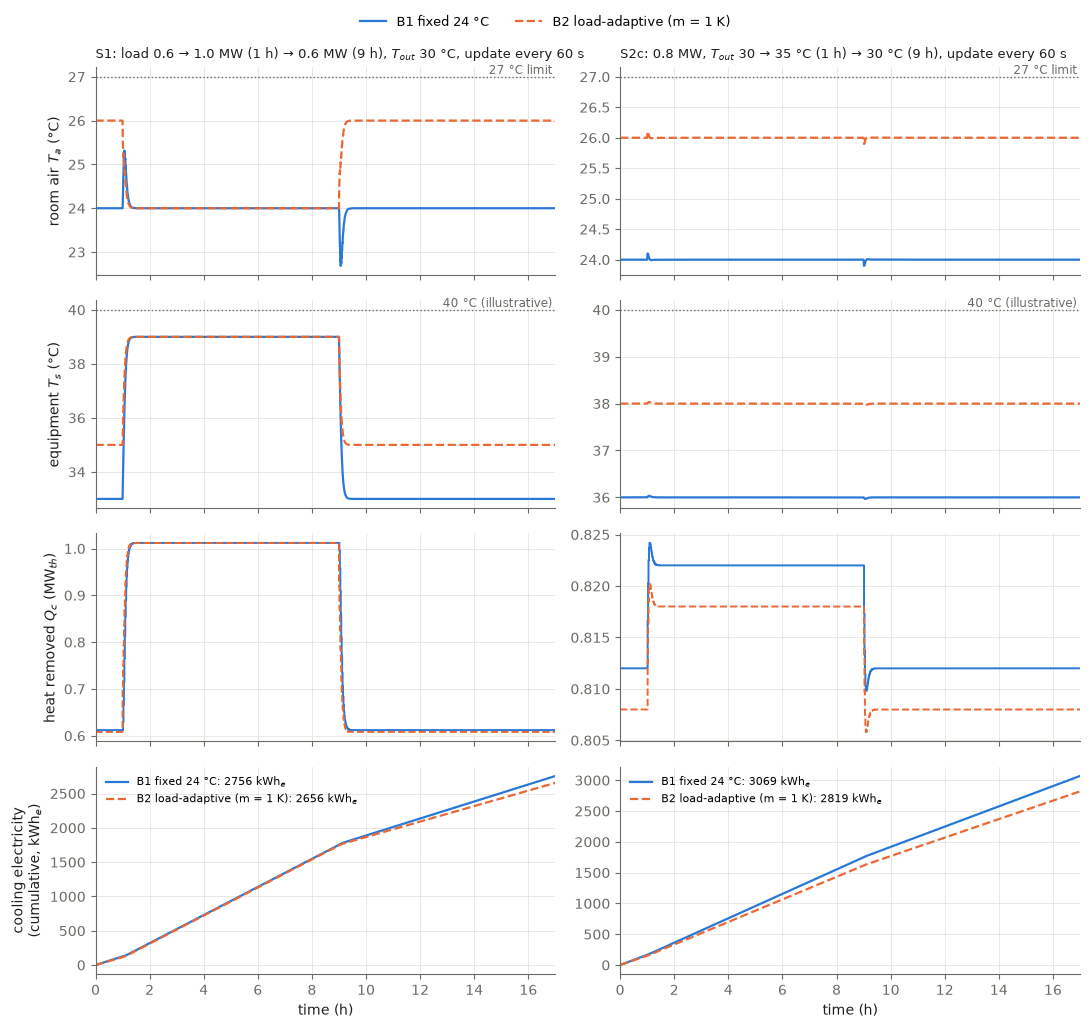

In [10]:
fig, axs = plt.subplots(4, 2, figsize=(11, 10), sharex=True)
for j, sid in enumerate(SCEN):
    for kind, v, col, ls, lab in (("B1", 24.0, BLUE, "-", "B1 fixed 24 °C"), ("B2", 1.0, ORANGE, "--", "B2 load-adaptive (m = 1 K)")):
        r = R5[(sid, 60, kind, v)]
        th = r.t / H
        axs[0, j].plot(th, r.X[:, 1], color=col, ls=ls, lw=1.6, label=lab)
        axs[1, j].plot(th, r.X[:, 0], color=col, ls=ls, lw=1.6, label=lab)
        axs[2, j].step(th, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.4, label=lab)
        axs[3, j].plot(th, tm.J_to_kWh(r.E_cool), color=col, ls=ls, lw=1.6, label=f"{lab}: {tm.J_to_kWh(r.E_cool[-1]):.0f} kWh$_e$")
    for ax, y, t in ((axs[0, j], 27.0, "27 °C limit"), (axs[1, j], 40.0, "40 °C (illustrative)")):
        ax.axhline(y, color=MUTED, ls=":", lw=1); ax.text(16.9, y, t, ha="right", va="bottom", fontsize=8.5, color=MUTED)
    axs[0, j].set_title(SCEN[sid]["title"] + ", update every 60 s", loc="left", fontsize=9.5, color=INK)
    axs[3, j].set_xlabel("time (h)")
    for ax in axs[:, j]:
        ax.set_xlim(0, 17); ax.grid(True, color=GRID, lw=0.6)
    axs[3, j].legend(frameon=False, fontsize=8, loc="upper left")
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper center", ncol=2, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 1.03))
axs[0, 0].set_ylabel("room air $T_a$ (°C)"); axs[1, 0].set_ylabel("equipment $T_s$ (°C)")
axs[2, 0].set_ylabel("heat removed $Q_c$ (MW$_{th}$)"); axs[3, 0].set_ylabel("cooling electricity\n(cumulative, kWh$_e$)")
fig.tight_layout(); save_fig(fig, "fig2_b1_b2_60s"); plt.show()

**Reading the comparison.**

- **Where the saving comes from.** B2 saves energy only while the load is below 1 MW, because then it runs the air 2 K warmer. The measured savings match the quasi-steady prediction made before simulating, so almost all of the effect is steady-state COP.
- **The cost is margin.** B2's equipment runs 2 K closer to the 40 °C illustrative limit.
- **S1 at 300 s.** B1 itself exceeds 27 °C after the load step, so no saving is claimed for that case.

## 6. Compact optimal-control benchmark (OC)

### 6.1 The discrete problem $\mathcal P_d$

On the update grid $t_k=k\,\Delta t$ ($N=204$ intervals at 300 s, $N=1020$ at 60 s):

$$\min_{u,x}\; J_d=\sum_{k=0}^{N-1}\Delta t\,\frac{u_k}{\mathrm{COP}(T_{a,k},T_{out,k})}
\quad\text{s.t.}\quad x_{k+1}=\Phi x_k+\Gamma[u_k,P_{IT,k},T_{out,k}]^\top,\;\; x_0=x_N=x_{start},$$
$$0\le u_k\le Q_{\max},\quad 18\le T_{a,k}\le27,\quad T_{s,k}\le40\quad\text{(at sample points)}.$$

- **Variant OC-ISC5** (separately labelled) also imposes the limits every 5 s inside each interval. Those constraints stay linear, because $x(t_k+\tau)=\Phi(\tau)x_k+\Gamma(\tau)w_k$.
- **Boundary protocols.** Each problem uses the start/end state of one PI controller (the B1 or the B2 protocol) and is compared **only** with that controller.
- **Solver.** IPOPT through CasADi (Wächter & Biegler, 2006; Andersson et al., 2019) from four starts: the matched PI warm start plus three seeded perturbations. The result is **best-found**, not proven globally optimal.
<div style="background:#e8f1fc;border-left:6px solid #2a78d6;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>LP lower bound (certified) — what its gap means</b><br>
On the COP domain $g=1/\mathrm{COP}$ is strictly decreasing in $T_a$: $\partial g/\partial T_a=-T_{cd}/(\eta_{II}T_{ev}^2)<0$. Every feasible point has $u_k\ge0$ and $T_{a,k}\le27$, so $u_k\,g(T_{a,k})\ge u_k\,g(27)$ term by term. The LP with cost $g(27,T_{out,k})$ and the <b>same</b> constraints therefore gives $J_{LB}\le J_d^\ast\le J_d(\text{best})$. It is solved with HiGHS (Huangfu & Hall, 2018) and certified by weak duality (Boyd & Vandenberghe, 2004): for any multipliers $y$, $b^\top y+\sum_i\min(r_il_i,r_iu_i)$ is a lower bound, where $r=c-A^\top y$. <br><b>The gap bounds suboptimality in $J_d$ only.</b> It says nothing about the replayed continuous-time electricity, nothing about safety between samples, and nothing about global continuous-time optimality.
</div>

<div style="background:#fdecef;border-left:6px solid #c0392b;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Loaded artifacts and cheap checks</b><br>
The best-found arrays are <b>loaded</b>. Everything else in this section is <b>recomputed</b>: the problem is rebuilt; feasibility, $J_d$, the replays on both grids, the energy balance and the LP certificate are all redone. Energy results always use the <b>replay-integrated electricity</b>, never $J_d$.
</div>

In [11]:
if RUN_FULL_OC:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts" / "export_oc_artifacts.py")], check=True, cwd=ROOT)
META = json.loads((ART / "oc_best_found.json").read_text())
ARR = np.load(ART / "oc_best_found.npz")
prov = META["provenance"]
print("LOADED artifacts/oc_best_found.npz + .json")
print(f"  created {prov['created_utc']} from {prov['source_notebook']}")
print(f"  versions: numpy {prov['numpy']}, scipy {prov['scipy']}, casadi {prov['casadi']}; cross-check: {prov['crosscheck_vs_notebook04_printed']}")

OCR = {}
t0 = time.perf_counter()
for tag, c in META["cases"].items():
    sid, dt, kind, var = c["scenario"], c["dt_s"], c["boundary_protocol"], c["variant"]
    u, x, xs = ARR[tag + "_u_W"], ARR[tag + "_x"], ARR[tag + "_x_start"]
    pi_x0 = R5[(sid, dt, kind, 24.0 if kind == "B1" else 1.0)].meta["x0"]
    prob = oc.build_problem(p, SCEN[sid]["dist"], xs, HORIZON, dt, T_a_band=T_A_BAND, T_s_max=T_S_MAX,
                            intersample_dt=5.0 if var == "OC-ISC5" else None, label=tag)
    chk = oc.check_point(prob, u, x)
    Jd = oc.J_d(prob, u, x[:, 1])
    lp, _ = oc.solve_lp(prob, time_limit=600.0)
    r5 = oc.replay(p, u, dt, SCEN[sid]["dist"], xs, HORIZON, fine_dt=FINE_DT)
    r1 = oc.replay(p, u, dt, SCEN[sid]["dist"], xs, HORIZON, fine_dt=FINE_DT_CHECK)
    a = assess(r5, r1, None)
    OCR[tag] = dict(meta=c, prob=prob, u=u, x=x, chk=chk, Jd=Jd, J_LB=lp.data["dual_bound"], r5=r5, r1=r1, a=a)
    ok = (np.array_equal(xs, pi_x0) and oc.is_feasible(chk, TOL_FEAS_K, TOL_FEAS_W)
          and abs(Jd - c["J_d_best_kWh_e"]) <= 1e-9 * Jd
          and abs(lp.data["dual_bound"] - c["J_LB_certified_kWh_e"]) <= TOL_LP * Jd
          and np.max(np.abs(r5.X[np.searchsorted(r5.t, prob.t), :2] - x)) < TOL_REPLAY
          and abs(r5.E_cool[-1] / 3.6e6 - c["replay_E_cool_5s_kWh_e"]) <= 1e-9 * Jd
          and abs(tm.energy_balance_residual(p, r5.X)) / r5.X[-1, 3] < 1e-9
          and abs(r1.E_cool[-1] - r5.E_cool[-1]) / r1.E_cool[-1] < 1e-6 and a["term_ok"])
    record(f"OC-{tag}", f"{tag}: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; "
           "replay = optimiser states; energy balance; 5 s vs 1 s; terminal",
           f"start matches PI {np.array_equal(xs, pi_x0)}; dyn {chk['dyn_K']:.0e} K, limits {max(chk['Ta_viol_K'], chk['Ts_viol_K'], chk['inter_viol_K']):.0e} K; "
           f"J_d {Jd:.4f} (stored {c['J_d_best_kWh_e']:.4f}); J_LB {lp.data['dual_bound']:.4f} (stored {c['J_LB_certified_kWh_e']:.4f}); "
           f"E_cool {r5.E_cool[-1]/3.6e6:.4f} (stored {c['replay_E_cool_5s_kWh_e']:.4f})", "all hold", ok)
print(f"16 OC cases checked (LP re-solved, 2 replays each) in {time.perf_counter() - t0:.0f} s")

LOADED artifacts/oc_best_found.npz + .json
  created 2026-10-29T20:34:46+00:00 from notebook/04_perfect_foresight_benchmark.ipynb (code cells 1-7 executed unchanged)
  versions: numpy 2.5.4, scipy 1.18.1, casadi 3.8.2; cross-check: all 16 cases identical to printed precision


[PASS] OC-S1_300_B1_OC: S1_300_B1_OC: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2537.6078 (stored 2537.6078); J_LB 2400.8044 (stored 2400.8044); E_cool 2539.0010 (stored 2539.0010)   criterion: all hold


[PASS] OC-S1_300_B2_OC: S1_300_B2_OC: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2534.9954 (stored 2534.9954); J_LB 2400.6218 (stored 2400.6218); E_cool 2535.4570 (stored 2535.4570)   criterion: all hold


[PASS] OC-S2c_300_B1_OC: S2c_300_B1_OC: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 2e-14 K, limits 0e+00 K; J_d 2701.6193 (stored 2701.6193); J_LB 2695.0549 (stored 2695.0549); E_cool 2702.6593 (stored 2702.6593)   criterion: all hold


[PASS] OC-S2c_300_B2_OC: S2c_300_B2_OC: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2698.1280 (stored 2698.1280); J_LB 2694.8725 (stored 2694.8725); E_cool 2698.2423 (stored 2698.2423)   criterion: all hold


...

[PASS] OC-S2c_60_B2_OC: S2c_60_B2_OC: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2697.0806 (stored 2697.0806); J_LB 2694.6438 (stored 2694.6438); E_cool 2697.5547 (stored 2697.5547)   criterion: all hold


[PASS] OC-S1_60_B1_OC-ISC5: S1_60_B1_OC-ISC5: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2503.5894 (stored 2503.5894); J_LB 2400.6944 (stored 2400.6944); E_cool 2553.3312 (stored 2553.3312)   criterion: all hold


[PASS] OC-S1_60_B2_OC-ISC5: S1_60_B2_OC-ISC5: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2502.5946 (stored 2502.5946); J_LB 2400.5853 (stored 2400.5853); E_cool 2550.3632 (stored 2550.3632)   criterion: all hold


[PASS] OC-S2c_60_B1_OC-ISC5: S2c_60_B1_OC-ISC5: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2699.0698 (stored 2699.0698); J_LB 2694.7529 (stored 2694.7529); E_cool 2702.0300 (stored 2702.0300)   criterion: all hold


[PASS] OC-S2c_60_B2_OC-ISC5: S2c_60_B2_OC-ISC5: loaded solution feasible for the rebuilt problem; J_d, certified LP bound and replay energy reproduce; replay = optimiser states; energy balance; 5 s vs 1 s; terminal
        measured: start matches PI True; dyn 1e-14 K, limits 0e+00 K; J_d 2697.0806 (stored 2697.0806); J_LB 2694.6438 (stored 2694.6438); E_cool 2697.5547 (stored 2697.5547)   criterion: all hold
16 OC cases checked (LP re-solved, 2 replays each) in 77 s


In [12]:
TAB_OC = ["OC benchmark vs matched PI (same boundary protocol) - replayed electricity; offline perfect-foresight best-found; illustrative",
          f"{'case':30s} {'E_PI':>7s} {'E_OC':>7s} {'saving':>8s} {'J_d,OC':>8s} {'J_LB':>8s} {'gap J_d':>8s} {'maxV 5s':>8s} {'maxV 1s':>9s} {'peak':>6s}  status",
          f"{'':30s} {'kWh_e':>7s} {'kWh_e':>7s} {'%':>8s} {'kWh_e':>8s} {'kWh_e':>8s} {'%':>8s} {'K':>8s} {'K':>9s} {'kW_e':>6s}"]
SAVE_OC = {}
for tag, o in OCR.items():
    c = o["meta"]
    sid, dt, kind, var = c["scenario"], c["dt_s"], c["boundary_protocol"], c["variant"]
    api = AS[(sid, dt, kind, 24.0 if kind == "B1" else 1.0)]
    E_pi, E_oc = api["e"]["E_cool_kWh_e"], o["a"]["e"]["E_cool_kWh_e"]
    ok = api["eligible"] and o["a"]["eligible"]
    if ok:
        SAVE_OC[tag] = (E_pi - E_oc) / E_pi
    if ok:
        st = "eligible: both safe on 5 s and 1 s grids, closed"
    else:
        st = "NOT eligible: " + "; ".join([f"PI {r}" for r in api["reasons"]] + [f"OC {r}" for r in o["a"]["reasons"]])
        if o["a"]["v5"]["within_limits"] and not o["a"]["v1"]["within_limits"]:
            st += f" -> diagnostic only, NOT continuously safe (1 s exceedance {o['a']['mv1']:.1e} K)"
    TAB_OC.append(f"{sid+' '+str(dt)+'s '+kind+'-prot '+var:30s} {E_pi:7.1f} {E_oc:7.1f} {(f'{100*(E_pi-E_oc)/E_pi:+.2f}' if ok else 'n/a'):>8s} "
                  f"{o['Jd']:8.1f} {o['J_LB']:8.1f} {100*(o['Jd']-o['J_LB'])/o['J_LB']:8.2f} {o['a']['mv5']:8.3f} {o['a']['mv1']:9.2e} "
                  f"{o['a']['e']['peak_P_cool_kW_e']:6.0f}  {st}")
print("\n".join(TAB_OC))
print("\nJ_d is the optimiser's discrete objective (left-endpoint COP); savings use replayed electricity only.")

OC benchmark vs matched PI (same boundary protocol) - replayed electricity; offline perfect-foresight best-found; illustrative
case                              E_PI    E_OC   saving   J_d,OC     J_LB  gap J_d  maxV 5s   maxV 1s   peak  status
                                 kWh_e   kWh_e        %    kWh_e    kWh_e        %        K         K   kW_e
S1 300s B1-prot OC              2756.7  2539.0      n/a   2537.6   2400.8     5.70    0.652  6.52e-01    208  NOT eligible: PI unsafe (5 s); OC unsafe (5 s)
S1 300s B2-prot OC              2656.2  2535.5      n/a   2535.0   2400.6     5.60    0.652  6.52e-01    201  NOT eligible: OC unsafe (5 s)
S2c 300s B1-prot OC             3069.4  2702.7   +11.95   2701.6   2695.1     0.24    0.000  0.00e+00    254  eligible: both safe on 5 s and 1 s grids, closed
S2c 300s B2-prot OC             2819.3  2698.2    +4.29   2698.1   2694.9     0.12    0.000  0.00e+00    176  eligible: both safe on 5 s and 1 s grids, closed
S1 300s B1-prot OC-ISC5         

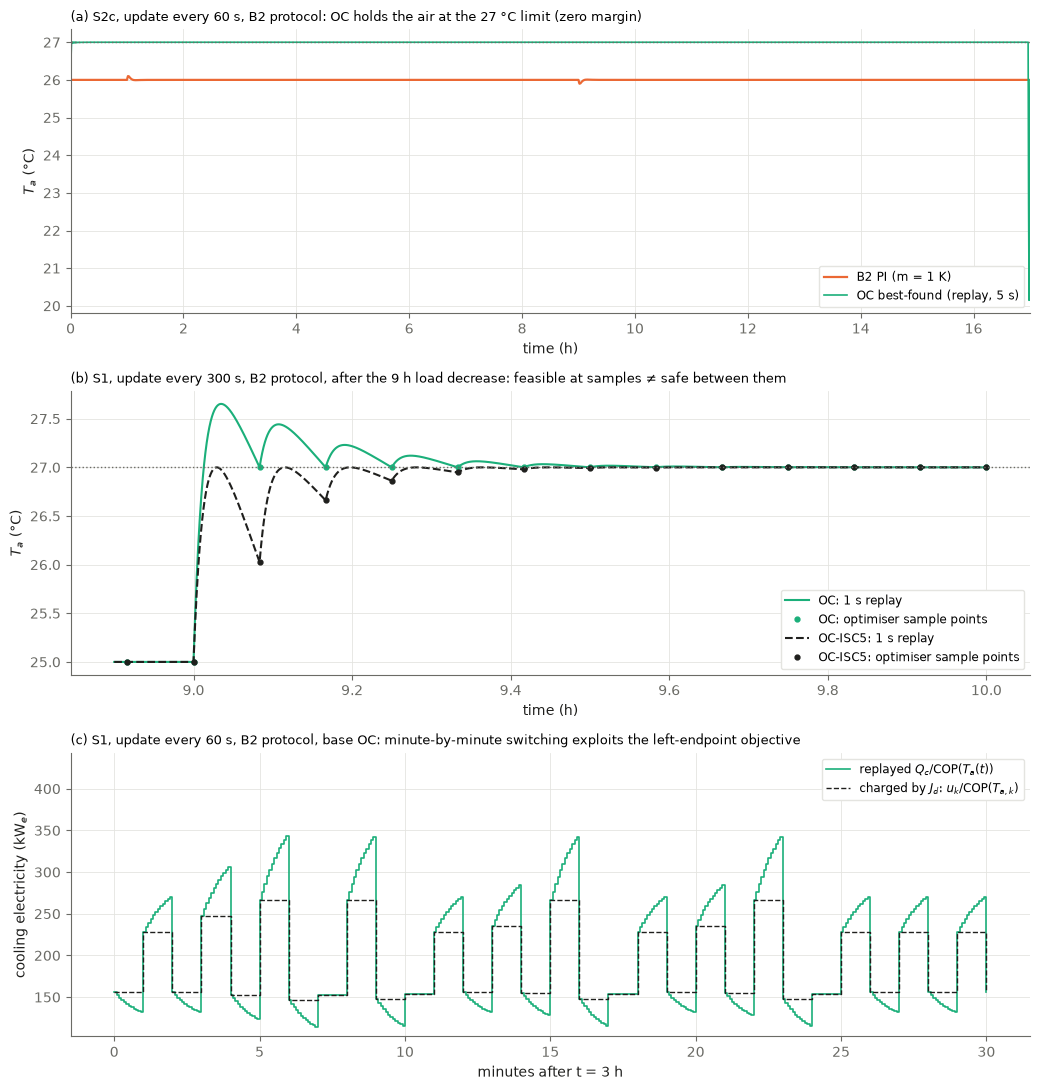

In [13]:
fig, axs = plt.subplots(3, 1, figsize=(10.5, 11))
# (a) S2c, 60 s, B2 protocol: OC rides the 27 C limit
r_pi, o = R5[("S2c", 60, "B2", 1.0)], OCR["S2c_60_B2_OC"]
axs[0].plot(r_pi.t / H, r_pi.X[:, 1], color=ORANGE, lw=1.6, label="B2 PI (m = 1 K)")
axs[0].plot(o["r5"].t / H, o["r5"].X[:, 1], color=GREEN, lw=1.2, label="OC best-found (replay, 5 s)")
axs[0].axhline(27, color=MUTED, ls=":", lw=1)
axs[0].set_title("(a) S2c, update every 60 s, B2 protocol: OC holds the air at the 27 °C limit (zero margin)", loc="left", fontsize=9.5)
axs[0].set_xlabel("time (h)"); axs[0].set_ylabel("$T_a$ (°C)"); axs[0].set_xlim(0, 17)
# (b) S1, 300 s, B2 protocol, after the 9 h load decrease: sample-point limits vs intersample behaviour
for var, col, ls in (("OC", GREEN, "-"), ("OC-ISC5", INK, "--")):
    oo = OCR[f"S1_300_B2_{var}"]
    z = (oo["r1"].t >= 8.9 * H) & (oo["r1"].t <= 10.0 * H)
    axs[1].plot(oo["r1"].t[z] / H, oo["r1"].X[z, 1], color=col, ls=ls, lw=1.5, label=f"{var}: 1 s replay")
    zk = (oo["prob"].t >= 8.9 * H) & (oo["prob"].t <= 10.0 * H)
    axs[1].plot(oo["prob"].t[zk] / H, oo["x"][zk, 1], ls="none", marker="o", ms=3.5, color=col, label=f"{var}: optimiser sample points")
axs[1].axhline(27, color=MUTED, ls=":", lw=1)
axs[1].set_title("(b) S1, update every 300 s, B2 protocol, after the 9 h load decrease: feasible at samples ≠ safe between them",
                 loc="left", fontsize=9.5)
axs[1].set_xlabel("time (h)"); axs[1].set_ylabel("$T_a$ (°C)")
# (c) S1, 60 s, B2 protocol, base OC: what J_d charges vs replayed electricity (chatter)
o = OCR["S1_60_B2_OC"]
r, prob = o["r5"], o["prob"]
z = (r.t >= 3 * H) & (r.t <= 3 * H + 1800)
zk = (prob.t[:-1] >= 3 * H) & (prob.t[:-1] <= 3 * H + 1800)
axs[2].step((r.t[z] - 3 * H) / 60, r.P_cool[z] / 1e3, where="post", color=GREEN, lw=1.2, label="replayed $Q_c/\\mathrm{COP}(T_a(t))$")
gk = 1.0 / tm.cop(p, o["x"][:-1][zk, 1], prob.T_out[zk])
axs[2].step((prob.t[:-1][zk] - 3 * H) / 60, o["u"][zk] * gk / 1e3, where="post", color=INK, ls="--", lw=1.0,
            label="charged by $J_d$: $u_k/\\mathrm{COP}(T_{a,k})$")
axs[2].set_title("(c) S1, update every 60 s, B2 protocol, base OC: minute-by-minute switching exploits the left-endpoint objective",
                 loc="left", fontsize=9.5)
axs[2].set_xlabel("minutes after t = 3 h"); axs[2].set_ylabel("cooling electricity (kW$_e$)")
axs[2].set_ylim(top=axs[2].get_ylim()[1] * 1.25)
for ax, loc in zip(axs, ("lower right", "lower right", "upper right")):
    ax.grid(True, color=GRID, lw=0.6); ax.legend(frameon=True, framealpha=1.0, edgecolor=GRID, fontsize=8.5, loc=loc)
fig.tight_layout(); save_fig(fig, "fig3_oc_benchmark"); plt.show()

**Reading the OC benchmark.**

- **Where OC's advantage comes from.** OC removes the margin rather than finding clever timing: it holds the air at 27 °C, or keeps the equipment at 40 °C at 1 MW (panel a). Its gain over B2 is roughly the cost of B2's 1 K margin. The drop at the very end of panel (a) is the forced return to B2's start state; the air stays above 18 °C.
- **Samples are not enough (panel b).** Sample-point feasibility does not imply safety between samples. The base OC overshoots 27 °C between updates in S1. OC-ISC5 removes that on the 5 s grid, but still exceeds by up to 4.8e-5 K (300 s) and 7.5e-4 K (60 s) on the 1 s grid. These S1 OC-ISC5 results are **diagnostic only and not continuously safe**, and they are not eligible under the strict rule.
- **J_d vs real electricity at 60 s (panel c).** The optimiser switches the cooling every minute. $J_d$ charges each minute at the COP of its starting temperature, so it under-counts the real electricity by about 48–56 kWh$_e$ in S1. The switching also raises peak cooling power to roughly 350–380 kW$_e$, against about 205 kW$_e$ for PI.

## 7. Sensitivity: B2 margin and B1 setpoint

These are one-at-a-time sweeps using the PI runs already computed above, with gains unchanged and the strict eligibility rule.

- **headroom** $=\min(27-T_{a,\max},\ T_{a,\min}-18,\ 40-T_{s,\max})$ on the 1 s grid; a negative value means a limit is exceeded.
- Savings are measured against B1 at 24 °C, and only where both runs are eligible.
- The OC results are **not** placed here. Their start and end states differ from these runs, so they would not be a matched comparison.

In [14]:
TAB_S = ["SENSITIVITY (strict eligibility; savings vs B1 24 C only when both eligible) - model results, illustrative",
         f"{'case':24s} {'start T_a':>9s} {'E_cool':>8s} {'vs B1-24':>9s} {'headroom':>9s}  status"]
for sid in SCEN:
    for dt in DTS:
        base = AS[(sid, dt, "B1", 24.0)]
        TAB_S.append(f"-- {sid} {dt}s")
        for kind, v in CTRLS:
            a = AS[(sid, dt, kind, v)]
            ok = a["eligible"] and base["eligible"]
            sav = "baseline" if (kind, v) == ("B1", 24.0) else (f"{100*(base['e']['E_cool_kWh_e']-a['e']['E_cool_kWh_e'])/base['e']['E_cool_kWh_e']:+.2f}" if ok else "n/a")
            TAB_S.append(f"{name(kind, v):24s} {R5[(sid, dt, kind, v)].meta['x0'][1]:9.2f} {a['e']['E_cool_kWh_e']:8.1f} {sav:>9s} {a['headroom']:9.3f}  "
                         + ("eligible" if a["eligible"] else "NOT eligible: " + ", ".join(a["reasons"])))
print("\n".join(TAB_S))

nb5 = ROOT / "notebook" / "05_margin_setpoint_sensitivity.ipynb"
if nb5.exists():
    txt = "\n".join("".join(o.get("text", "")) for c in json.loads(nb5.read_text())["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
    tab = txt[txt.rfind("SENSITIVITY (model"):]
    ref, blk = {}, None
    for l in tab.splitlines():
        m = re.match(r"-- (\S+) (\d+)s", l)
        if m:
            blk = (m[1], int(m[2])); continue
        m = re.match(r"(B[12] (?:\d+ C|m=\S+ K))\s+\S+\s+(\d+\.\d)", l)
        if m and blk:
            ref[blk + (m[1],)] = m[2]
    now = {(k[0], k[1], name(k[2], k[3])): f"{AS[k]['e']['E_cool_kWh_e']:.1f}" for k in AS}
    n_ok = sum(now[k] == ref.get(k) for k in now)
    record("S1", "sensitivity energies reproduce notebook 05 (28 runs)", f"{n_ok}/28 identical", "28/28 to the printed 0.1 kWh_e", n_ok == 28)

SENSITIVITY (strict eligibility; savings vs B1 24 C only when both eligible) - model results, illustrative
case                     start T_a   E_cool  vs B1-24  headroom  status
-- S1 60s
B1 23 C                      23.00   2879.7     -4.47     2.000  eligible
B1 24 C                      24.00   2756.5  baseline     1.000  eligible
B1 25 C                      25.00   2634.6     +4.42    -0.000  eligible
B2 m=0.5 K                   26.50   2595.8     +5.83     0.500  eligible
B2 m=1 K                     26.00   2656.2     +3.64     1.000  eligible
B2 m=1.5 K                   25.50   2717.1     +1.43     1.500  eligible
B2 m=2 K                     25.00   2778.2     -0.79     2.000  eligible
-- S1 300s
B1 23 C                      23.00   2880.0       n/a     0.564  eligible
B1 24 C                      24.00   2756.7  baseline    -0.436  NOT eligible: unsafe (5 s)
B1 25 C                      25.00   2634.8       n/a    -1.436  NOT eligible: unsafe (5 s)
B2 m=0.5 K              

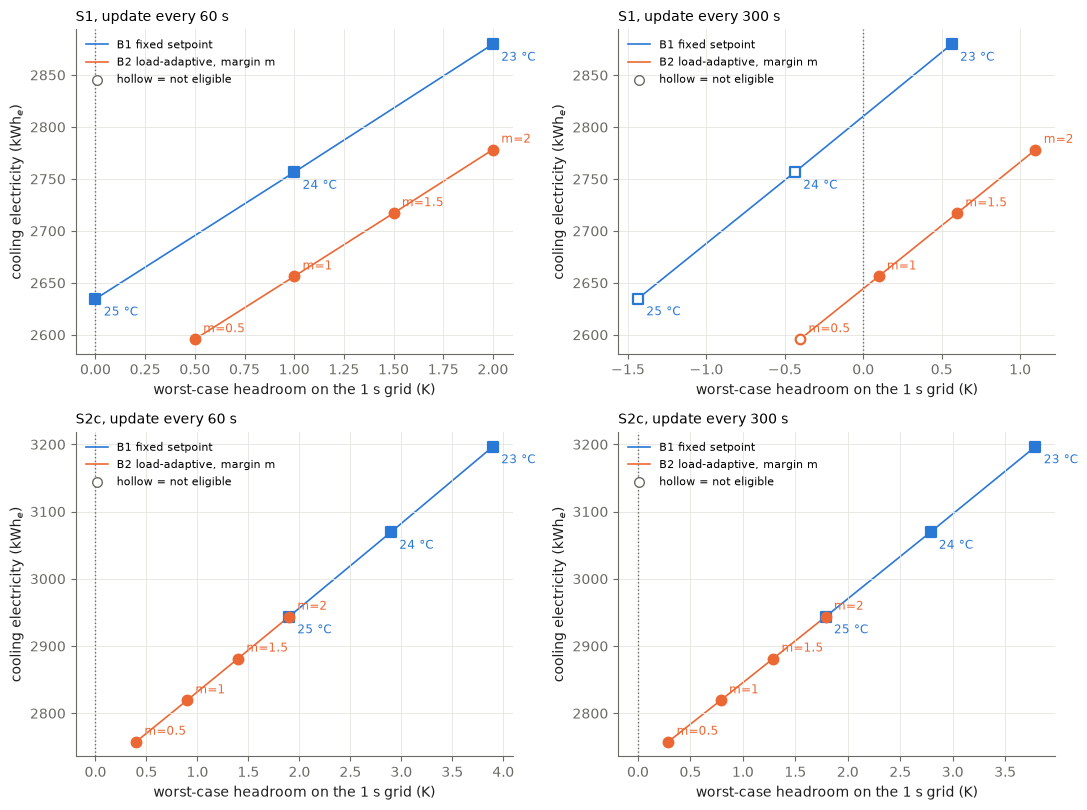

In [15]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8.2))
for i, sid in enumerate(SCEN):
    for j, dt in enumerate(DTS):
        ax = axs[i, j]
        for kind, col, mk, lab in (("B1", BLUE, "s", "B1 fixed setpoint"), ("B2", ORANGE, "o", "B2 load-adaptive, margin m")):
            keys = [(sid, dt, k, v) for k, v in CTRLS if k == kind]
            xs = [AS[k]["headroom"] for k in keys]; ys = [AS[k]["e"]["E_cool_kWh_e"] for k in keys]
            ax.plot(xs, ys, color=col, lw=1.2, zorder=1, label=lab)
            for k, xx, yy in zip(keys, xs, ys):
                ax.scatter([xx], [yy], s=48, marker=mk, color=col if AS[k]["eligible"] else "white", edgecolor=col, linewidth=1.6, zorder=2)
                ax.annotate(f"{k[3]:.0f} °C" if kind == "B1" else f"m={k[3]:g}", (xx, yy), textcoords="offset points",
                            xytext=(6, 5 if kind == "B2" else -12), fontsize=8.5, color=col)
        ax.axvline(0, color=MUTED, ls=":", lw=1)
        ax.set_title(f"{sid}, update every {dt} s", loc="left", fontsize=10)
        ax.set_xlabel("worst-case headroom on the 1 s grid (K)"); ax.set_ylabel("cooling electricity (kWh$_e$)")
        ax.grid(True, color=GRID, lw=0.6)
        ax.scatter([], [], s=48, marker="o", color="white", edgecolor=MUTED, label="hollow = not eligible")
        ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig4_sensitivity"); plt.show()

**Reading the sweep.**

- **Margin costs energy at a steady rate.** Each extra 0.5 K of margin costs about 60–62 kWh$_e$ over 17 h, roughly 2 % of the baseline.
- **Load adaptation beats a warmer fixed setpoint when the load varies (S1).** At equal headroom, B2 uses about 100 kWh$_e$ less than B1. A fixed setpoint must be safe at the 1 MW peak, so it is too cold at low load.
- **With constant load (S2c) there is nothing to adapt to.** B2 at $m=2$ and B1 at 25 °C are the same controller and give identical energy. B2's S2c "saving" is purely a warmer setpoint.
- **The update interval affects safety, not energy.** At 300 s, B1 at 24 °C (the baseline), B1 at 25 °C and B2 at $m=0.5$ exceed a limit in S1.

## 8. Conclusions (scoped to the tested cases)

1. **The model.** A two-node lumped model, discretised exactly by the matrix exponential, reproduces an independent stiff solver to below $10^{-6}$ K and conserves energy to round-off. Its two time scales (about 46 s for the air, about 4.07 h for the equipment) explain why a 300 s update can miss fast air excursions.
2. **Load-adaptive setpoint.** In both synthetic scenarios, at 60 s updates, adapting the setpoint to the measured load (B2, $m=1$ K) used 3.6 % (S1) and 8.2 % (S2c) less cooling electricity than a fixed 24 °C setpoint, with both runs safe on the 5 s and 1 s grids. This matches a quasi-steady COP prediction made beforehand. The saving is paid for with thermal margin: the equipment runs 2 K closer to the illustrative 40 °C limit.
3. **Margin is the main lever.** The sensitivity sweep shows energy falling roughly linearly as headroom shrinks. Load adaptation helps only when the load varies.
4. **The optimal-control benchmark** (offline, perfect foresight, best-found) gains mainly by running with **zero margin**, not by timing. Its S1 solutions need intersample constraints and still graze the limits on a 1 s grid, so they are diagnostic, not continuously safe. At 60 s its discrete objective under-counts the real electricity because of minute-by-minute switching.
5. **Limits of the study.** Illustrative parameters, two step scenarios, $\kappa=0$, no real COP curves, no fan power, no real data, and no validation against a real facility. The numerical checks are verification, not validation.

**Future work:**
- calibrate the parameters against real facility data;
- use realistic load and weather traces;
- model temperature-dependent server power ($\kappa>0$), which could cancel the warm-side savings above roughly 0.7 %/K;
- use a better objective quadrature, or a switching penalty, for OC;
- build a model-predictive controller with imperfect forecasts (Rawlings et al., 2017).

## AI acknowledgement
<!-- OUTSTANDING: to be written by the team from AI_USE_LOG.md before submission. Intentionally left blank. -->

## Summary of checks, runtime and dependencies

In [16]:
elapsed = time.perf_counter() - T_START
failed = [r for r in results if not r[4]]
print(f"MAIN NOTEBOOK: {sum(r[4] for r in results)}/{len(results)} checks passed; runtime {elapsed/60:.1f} min")
for r in results:
    print(f"  {'PASS' if r[4] else 'FAIL'}  {r[0]}")
print("loaded:     artifacts/oc_best_found.npz/.json (best-found OC arrays; optimisation not re-run)" if not RUN_FULL_OC else "OC re-optimised in this run")
print("recomputed: model checks, gain design, all 56 PI simulations, OC feasibility/J_d/LP certificates/replays, tables, figures")
print(f"figures written to {FIG.relative_to(ROOT)}/ (png, eps, pdf)")
print(f"dependencies: python {sys.version.split()[0]}, numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, casadi {casadi.__version__}")
assert not failed, f"unresolved failures: {[r[0] for r in failed]}"

MAIN NOTEBOOK: 28/28 checks passed; runtime 3.1 min
  PASS  M1
  PASS  M2
  PASS  M3
  PASS  M4
  PASS  P1-60
  PASS  P1-300
  PASS  E1
  PASS  E2
  PASS  E3
  PASS  E4
  PASS  E5
  PASS  OC-S1_300_B1_OC
  PASS  OC-S1_300_B2_OC
  PASS  OC-S2c_300_B1_OC
  PASS  OC-S2c_300_B2_OC
  PASS  OC-S1_300_B1_OC-ISC5
  PASS  OC-S1_300_B2_OC-ISC5
  PASS  OC-S2c_300_B1_OC-ISC5
  PASS  OC-S2c_300_B2_OC-ISC5
  PASS  OC-S1_60_B1_OC
  PASS  OC-S1_60_B2_OC
  PASS  OC-S2c_60_B1_OC
  PASS  OC-S2c_60_B2_OC
  PASS  OC-S1_60_B1_OC-ISC5
  PASS  OC-S1_60_B2_OC-ISC5
  PASS  OC-S2c_60_B1_OC-ISC5
  PASS  OC-S2c_60_B2_OC-ISC5
  PASS  S1
loaded:     artifacts/oc_best_found.npz/.json (best-found OC arrays; optimisation not re-run)
recomputed: model checks, gain design, all 56 PI simulations, OC feasibility/J_d/LP certificates/replays, tables, figures
figures written to figures/main/ (png, eps, pdf)
dependencies: python 3.14.7, numpy 2.5.4, scipy 1.18.1, matplotlib 3.11.2, casadi 3.8.2
